# Sales Forecasting NetSales MyVentory (Harian)

Prediksi **NetSales** total seluruh outlet per **hari** memakai tiga model:

| Model | Jenis | Keterangan |
|---|---|---|
| SARIMA | statistik | order dicari dengan grid AIC, musiman mingguan 7 hari |
| ETS (Holt-Winters) | statistik | tren aditif damping + musiman mingguan |
| Gradient Boosting | machine learning | fitur lag harian + kalender |

Pembanding: **baseline seasonal-naive** (nilai 7 hari sebelumnya).

- Sumber data: `data/Transactions.csv` (transaksi 3 outlet, Januari - September 2025)
- Target: `NetSales` dijumlahkan per hari
- Data uji: 28 hari terakhir
- Model tersimpan meramal **1 minggu (7 hari)** ke depan
- Semua hasil (model, metadata, CSV, grafik) disimpan di folder yang sama: `artifacts/sales_forecast/`

## 1. Konfigurasi

Seluruh pengaturan ada di satu tempat, termasuk satu folder keluaran untuk model, metadata, CSV, dan grafik.

In [1]:
import json
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

DATA_PATH = Path("..") / "data" / "Transactions.csv"
OUTPUT_DIR = Path("..") / "artifacts" / "sales_forecast"
MODEL_PATH = OUTPUT_DIR / "model.pkl"
METADATA_PATH = OUTPUT_DIR / "metadata.json"

TEST_DAYS = 28      # hari terakhir sebagai data uji
SEASON_LENGTH = 7   # pola mingguan
HORIZON_DAYS = 7    # model disimpan meramal 1 minggu ke depan
SEED = 42

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("pandas      :", pd.__version__)
print("folder hasil:", OUTPUT_DIR.resolve())

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


pandas      : 3.0.3
folder hasil: C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\sales_forecast


## 2. Memuat dan mengagregasi data

Satu baris transaksi = satu struk. NetSales dijumlahkan per tanggal sehingga terbentuk deret waktu harian.

In [2]:
transactions = pd.read_csv(DATA_PATH, parse_dates=["Date"])

daily = transactions.groupby("Date").NetSales.sum().asfreq("D")

assert daily.notna().all(), "ada tanggal tanpa transaksi"
assert not daily.index.duplicated().any(), "ada tanggal duplikat"

print(f"baris transaksi : {len(transactions):,}")
print(f"outlet          : {sorted(transactions.Outlet.unique())}")
print(f"rentang tanggal : {daily.index.min().date()} s/d {daily.index.max().date()}")
print(f"jumlah hari     : {len(daily)}")
print()
print("NetSales per bulan (juta rupiah):")
print((daily.resample("MS").sum() / 1e6).round(1).to_string())

baris transaksi : 53,820
outlet          : ['SHOP001', 'SHOP002', 'SHOP003']
rentang tanggal : 2025-01-02 s/d 2025-09-30
jumlah hari     : 272

NetSales per bulan (juta rupiah):
Date
2025-01-01    118.2
2025-02-01    134.4
2025-03-01    137.3
2025-04-01     99.3
2025-05-01    119.5
2025-06-01    164.7
2025-07-01    158.8
2025-08-01    131.2
2025-09-01    121.6
Freq: MS


## 3. Eksplorasi awal

Melihat skala nilai, pola hari kerja, dan kekuatan pola mingguan.

In [3]:
print("Statistik harian NetSales (juta rupiah):")
print((daily.describe() / 1e6).round(2).to_string())
print()
print("Rata-rata per hari dalam minggu (juta rupiah):")
dow_mean = daily.groupby(daily.index.dayofweek).mean() / 1e6
dow_mean.index = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
print(dow_mean.round(2).to_string())

Statistik harian NetSales (juta rupiah):
count    0.00
mean     4.36
std      0.73
min      2.76
25%      3.81
50%      4.30
75%      4.88
max      6.31

Rata-rata per hari dalam minggu (juta rupiah):
Senin     4.32
Selasa    4.36
Rabu      4.36
Kamis     4.36
Jumat     4.41
Sabtu     4.26
Minggu    4.43


In [4]:
from statsmodels.tsa.seasonal import STL

stl = STL(daily, period=SEASON_LENGTH, robust=True).fit()
strength = max(0.0, 1 - stl.resid.var() / daily.var())

print(f"kekuatan pola mingguan (0 sampai 1): {strength:.3f}")
print("nilai di atas 0.5 berarti pola mingguan jelas dan layak dimodelkan.")

kekuatan pola mingguan (0 sampai 1): 0.770
nilai di atas 0.5 berarti pola mingguan jelas dan layak dimodelkan.


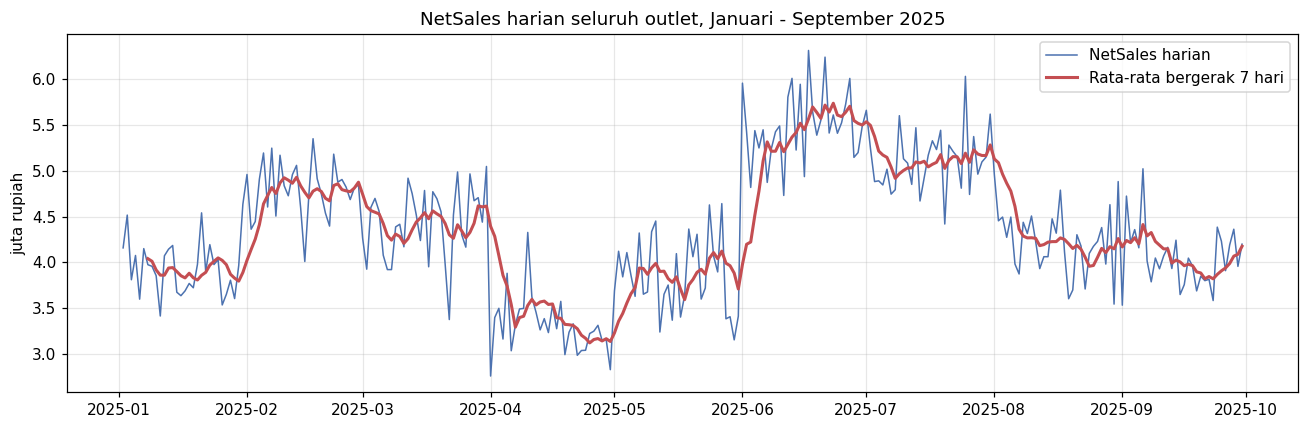

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily / 1e6, lw=1, color="#4c72b0", label="NetSales harian")
ax.plot(daily.index, daily.rolling(7).mean() / 1e6, lw=2, color="#c44e52", label="Rata-rata bergerak 7 hari")
ax.set_title("NetSales harian seluruh outlet, Januari - September 2025")
ax.set_ylabel("juta rupiah")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_1_series.png", dpi=120)
plt.show()

## 4. Membagi data latih dan data uji

28 hari terakhir dipakai sebagai data uji, 244 hari sebelumnya sebagai data latih.
Baseline seasonal-naive menjadi acuan minimal yang harus dikalahkan model.

In [6]:
train = daily.iloc[:-TEST_DAYS]
test = daily.iloc[-TEST_DAYS:]

y_train = train.to_numpy(dtype=float)
y_test = test.to_numpy(dtype=float)

# baseline seasonal-naive: ulangi pola 7 hari terakhir data latih
forecast_baseline = np.repeat(train.iloc[-SEASON_LENGTH:].to_numpy(dtype=float), TEST_DAYS // SEASON_LENGTH)

print(f"data latih : {train.index.min().date()} s/d {train.index.max().date()} ({len(train)} hari)")
print(f"data uji   : {test.index.min().date()} s/d {test.index.max().date()} ({len(test)} hari)")
print(f"rata-rata data latih : Rp {y_train.mean():,.0f}")
print(f"rata-rata data uji   : Rp {y_test.mean():,.0f}")

data latih : 2025-01-02 s/d 2025-09-02 (244 hari)
data uji   : 2025-09-03 s/d 2025-09-30 (28 hari)
rata-rata data latih : Rp 4,391,803
rata-rata data uji   : Rp 4,047,619


## 5. Model 1 - SARIMA

Pencarian grid kecil berdasarkan AIC. Komponen musiman memakai periode 7 (mingguan). Kombinasi yang gagal konvergen dilewati.

In [7]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

grid_result = []
for p in range(3):
    for q in range(3):
        for P in range(2):
            for Q in range(2):
                try:
                    candidate = SARIMAX(
                        y_train,
                        order=(p, 1, q),
                        seasonal_order=(P, 1, Q, SEASON_LENGTH),
                        enforce_stationarity=False,
                        enforce_invertibility=False,
                    ).fit(disp=False)
                    grid_result.append({"p": p, "d": 1, "q": q, "P": P, "D": 1, "Q": Q, "AIC": candidate.aic})
                except Exception:
                    pass

grid_table = pd.DataFrame(grid_result).sort_values("AIC").reset_index(drop=True)
print(f"kombinasi berhasil diuji: {len(grid_table)} dari 36")
print()
print("lima order terbaik:")
print(grid_table.head(5).round(1).to_string(index=False))

C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Radit\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


kombinasi berhasil diuji: 36 dari 36

lima order terbaik:
 p  d  q  P  D  Q    AIC
 0  1  2  1  1  1 6625.3
 0  1  2  0  1  1 6628.0
 0  1  1  1  1  1 6652.8
 1  1  1  1  1  1 6654.7
 0  1  1  0  1  1 6655.4


In [8]:
first = grid_table.loc[0]
best_p, best_q = int(first.p), int(first.q)
best_P, best_Q = int(first.P), int(first.Q)

print(f"order terpilih: ({best_p}, 1, {best_q}) x ({best_P}, 1, {best_Q}, {SEASON_LENGTH})")
print(f"AIC           : {first.AIC:,.1f}")

sarima = SARIMAX(
    y_train,
    order=(best_p, 1, best_q),
    seasonal_order=(best_P, 1, best_Q, SEASON_LENGTH),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

forecast_sarima = np.asarray(sarima.forecast(TEST_DAYS), dtype=float)
print("tujuh prediksi pertama (rupiah):", np.round(forecast_sarima[:7]).astype(int).tolist())

order terpilih: (0, 1, 2) x (1, 1, 1, 7)
AIC           : 6,625.3
tujuh prediksi pertama (rupiah): [4190226, 4288502, 4517783, 4027944, 4531302, 4119874, 4245854]


## 6. Model 2 - ETS (Holt-Winters)

Tren aditif dengan damping dan komponen musiman mingguan. Parameter smoothing diestimasi otomatis.

In [9]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

ets = ETSModel(
    y_train,
    error="add",
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=SEASON_LENGTH,
).fit(disp=False)

forecast_ets = np.asarray(ets.forecast(TEST_DAYS), dtype=float)

smoothing = dict(zip(ets.param_names, ets.params))
print("parameter smoothing hasil estimasi:")
print({key: round(float(smoothing[key]), 4) for key in ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]})
print("tujuh prediksi pertama (rupiah):", np.round(forecast_ets[:7]).astype(int).tolist())

parameter smoothing hasil estimasi:
{'smoothing_level': 0.3262, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.036, 'damping_trend': 0.8677}
tujuh prediksi pertama (rupiah): [4265051, 4230290, 4416785, 4164843, 4349951, 4237943, 4304174]


## 7. Model 3 - Gradient Boosting

Model belajar dari fitur yang dibentuk sendiri:

- `lag1` ... `lag28`: nilai NetSales beberapa hari sebelumnya;
- `roll_mean_7/14/28` dan `roll_std_7`: ringkasan pergerakan jangka pendek;
- `dow`, `is_weekend`, `day`, `month`, `day_of_year`: informasi kalender.

Semua fitur hanya memakai data sebelum hari yang diprediksi, jadi tidak ada kebocoran informasi.

In [10]:
LAGS = [1, 2, 3, 7, 14, 21, 28]
FEATURE_NAMES = (
    [f"lag{lag}" for lag in LAGS]
    + ["roll_mean_7", "roll_mean_14", "roll_mean_28", "roll_std_7"]
    + ["dow", "is_weekend", "day", "month", "day_of_year"]
)

rows = []
targets = []
for position in range(max(LAGS), len(y_train)):
    row = [y_train[position - lag] for lag in LAGS]
    row.append(np.mean(y_train[position - 7:position]))
    row.append(np.mean(y_train[position - 14:position]))
    row.append(np.mean(y_train[position - 28:position]))
    row.append(np.std(y_train[position - 7:position], ddof=1))
    date = train.index[position]
    row.extend([date.dayofweek, int(date.dayofweek >= 5), date.day, date.month, date.dayofyear])
    rows.append(row)
    targets.append(y_train[position])

X_train = pd.DataFrame(rows, columns=FEATURE_NAMES)
targets = np.array(targets, dtype=float)

print("bentuk matriks latih:", X_train.shape)
print("contoh baris terakhir:")
print(X_train.tail(1).round(1).to_string(index=False))

bentuk matriks latih: (216, 16)
contoh baris terakhir:
     lag1      lag2      lag3      lag7     lag14     lag21     lag28  roll_mean_7  roll_mean_14  roll_mean_28  roll_std_7  dow  is_weekend  day  month  day_of_year
3533333.4 4881982.0 3545045.1 4228828.9 3603603.6 3932432.5 4494594.6    4168725.9     4067567.6     4162226.5    515939.1    1           0    2      9          245


In [11]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    random_state=SEED,
)
gbr.fit(X_train, targets)

print(f"R2 pada data latih: {gbr.score(X_train, targets):.4f}")
print()
print("delapan fitur paling berpengaruh:")
importance = pd.Series(gbr.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
print(importance.head(8).round(3).to_string())

R2 pada data latih: 0.9923

delapan fitur paling berpengaruh:
roll_mean_7     0.335
lag1            0.224
day             0.065
day_of_year     0.064
lag2            0.062
roll_std_7      0.044
roll_mean_14    0.042
lag28           0.031


In [12]:
# prediksi 28 hari dilakukan bertahap: hasil hari ini dipakai sebagai lag untuk hari berikutnya
history = list(y_train)
forecast_gbr = []

for date in pd.date_range(test.index[0], periods=TEST_DAYS, freq="D"):
    row = [history[-lag] for lag in LAGS]
    row.append(np.mean(history[-7:]))
    row.append(np.mean(history[-14:]))
    row.append(np.mean(history[-28:]))
    row.append(np.std(history[-7:], ddof=1))
    row.extend([date.dayofweek, int(date.dayofweek >= 5), date.day, date.month, date.dayofyear])
    prediction = gbr.predict(pd.DataFrame([row], columns=FEATURE_NAMES))[0]
    forecast_gbr.append(prediction)
    history.append(prediction)

forecast_gbr = np.array(forecast_gbr, dtype=float)
print("tujuh prediksi pertama (rupiah):", np.round(forecast_gbr[:7]).astype(int).tolist())

tujuh prediksi pertama (rupiah): [4084632, 4320346, 3970089, 4090696, 4058671, 4092551, 4261036]


## 8. Evaluasi model

Metrik: MAE dan RMSE (rupiah), MAPE dan sMAPE (persen), serta bias untuk melihat kecenderungan over/under-prediksi.

In [13]:
forecast_lookup = {
    "Baseline naive-7": forecast_baseline,
    "SARIMA": forecast_sarima,
    "ETS": forecast_ets,
    "Gradient Boosting": forecast_gbr,
}

evaluations = []
for name, forecast in forecast_lookup.items():
    error = y_test - forecast
    evaluations.append({
        "model": name,
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE_%": np.mean(np.abs(error) / y_test) * 100,
        "sMAPE_%": np.mean(2 * np.abs(error) / (np.abs(y_test) + np.abs(forecast))) * 100,
        "bias": np.mean(forecast - y_test),
    })

metrics = pd.DataFrame(evaluations).sort_values("MAE").reset_index(drop=True)
best_name = metrics.loc[0, "model"]

print("Evaluasi 28 hari terakhir, diurutkan dari MAE terkecil:")
print(metrics.round(2).to_string(index=False))
print()
print(f"model terbaik: {best_name}")

Evaluasi 28 hari terakhir, diurutkan dari MAE terkecil:
            model       MAE      RMSE  MAPE_%  sMAPE_%      bias
Gradient Boosting 255669.31 331500.41    6.41     6.24 135572.98
              ETS 315290.67 388251.82    7.98     7.64 233698.08
           SARIMA 321532.66 414731.01    8.04     7.70 206067.37
 Baseline naive-7 474002.58 585738.97   11.78    11.24 191763.19

model terbaik: Gradient Boosting


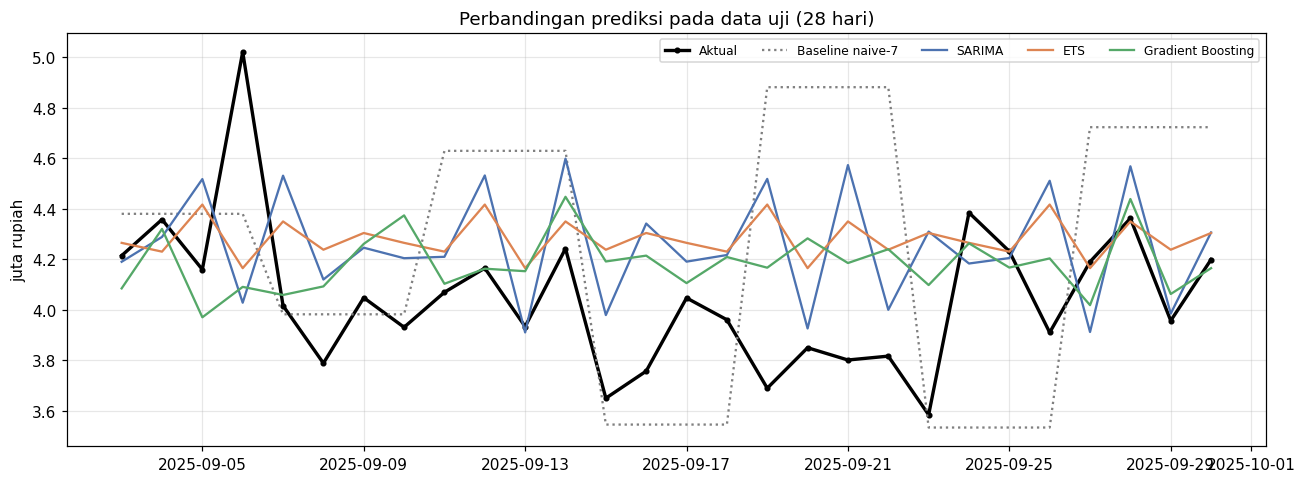

In [14]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(test.index, y_test / 1e6, color="black", lw=2.2, marker="o", ms=3, label="Aktual")
ax.plot(test.index, forecast_baseline / 1e6, ls=":", color="gray", label="Baseline naive-7")
ax.plot(test.index, forecast_sarima / 1e6, color="#4c72b0", label="SARIMA")
ax.plot(test.index, forecast_ets / 1e6, color="#dd8452", label="ETS")
ax.plot(test.index, forecast_gbr / 1e6, color="#55a868", label="Gradient Boosting")
ax.set_title("Perbandingan prediksi pada data uji (28 hari)")
ax.set_ylabel("juta rupiah")
ax.legend(ncol=5, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_2_test_zoom.png", dpi=120)
plt.show()

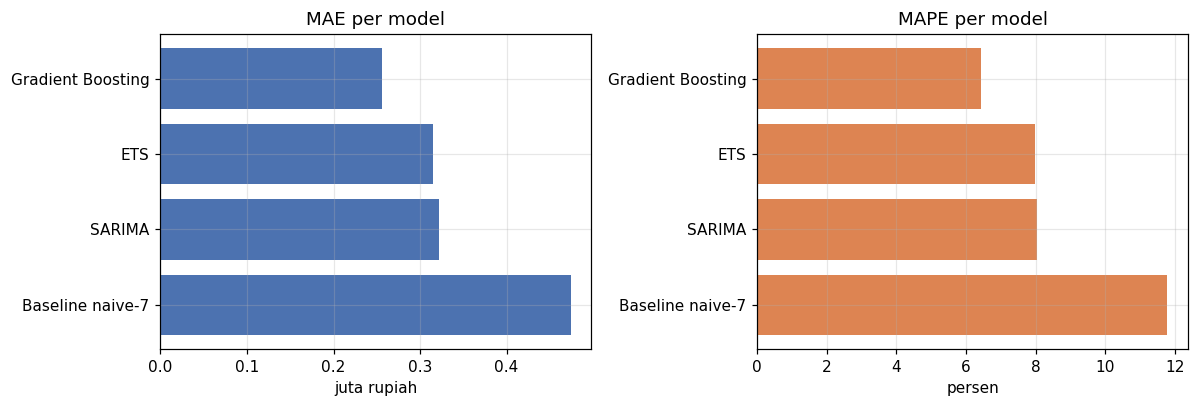

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].barh(metrics["model"], metrics["MAE"] / 1e6, color="#4c72b0")
axes[0].set_title("MAE per model")
axes[0].set_xlabel("juta rupiah")
axes[0].invert_yaxis()

axes[1].barh(metrics["model"], metrics["MAPE_%"], color="#dd8452")
axes[1].set_title("MAPE per model")
axes[1].set_xlabel("persen")
axes[1].invert_yaxis()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_metrics.png", dpi=120)
plt.show()

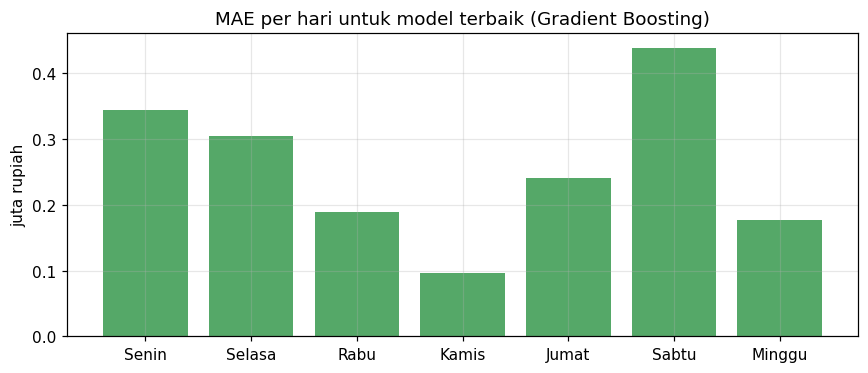

Senin     0.344
Selasa    0.305
Rabu      0.188
Kamis     0.096
Jumat     0.241
Sabtu     0.439
Minggu    0.177


In [16]:
best_forecast = forecast_lookup[best_name]
error_frame = pd.DataFrame({
    "dow": test.index.dayofweek,
    "abs_error": np.abs(y_test - best_forecast),
})
error_by_dow = error_frame.groupby("dow").abs_error.mean() / 1e6
error_by_dow.index = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(error_by_dow.index, error_by_dow.values, color="#55a868")
ax.set_title(f"MAE per hari untuk model terbaik ({best_name})")
ax.set_ylabel("juta rupiah")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_4_error_dow.png", dpi=120)
plt.show()

print(error_by_dow.round(3).to_string())

## 9. Ekspor model terbaik ke pickle

Hanya **satu** model yang disimpan: model terbaik dari tabel di atas, dilatih ulang memakai **seluruh 272 hari**.
Model ini meramal **1 minggu (7 hari)** ke depan.

In [17]:
full_y = daily.to_numpy(dtype=float)

sarima_full = SARIMAX(
    full_y,
    order=(best_p, 1, best_q),
    seasonal_order=(best_P, 1, best_Q, SEASON_LENGTH),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

ets_full = ETSModel(
    full_y,
    error="add",
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=SEASON_LENGTH,
).fit(disp=False)

full_rows = []
full_targets = []
for position in range(max(LAGS), len(full_y)):
    row = [full_y[position - lag] for lag in LAGS]
    row.append(np.mean(full_y[position - 7:position]))
    row.append(np.mean(full_y[position - 14:position]))
    row.append(np.mean(full_y[position - 28:position]))
    row.append(np.std(full_y[position - 7:position], ddof=1))
    date = daily.index[position]
    row.extend([date.dayofweek, int(date.dayofweek >= 5), date.day, date.month, date.dayofyear])
    full_rows.append(row)
    full_targets.append(full_y[position])

gbr_full = GradientBoostingRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    random_state=SEED,
)
gbr_full.fit(pd.DataFrame(full_rows, columns=FEATURE_NAMES), np.array(full_targets, dtype=float))

print(f"ketiga model dilatih ulang pada seluruh {len(full_y)} hari")

ketiga model dilatih ulang pada seluruh 272 hari


In [18]:
# hanya model terbaik yang dibungkus untuk disimpan
candidates = {
    "SARIMA": {
        "model": sarima_full,
        "freq": "D",
        "order": (best_p, 1, best_q),
        "seasonal_order": (best_P, 1, best_Q, SEASON_LENGTH),
        "horizon_days": HORIZON_DAYS,
        "last_date": daily.index.max(),
        "mae_test": float(metrics.set_index("model").loc["SARIMA", "MAE"]),
    },
    "ETS": {
        "model": ets_full,
        "freq": "D",
        "seasonal_periods": SEASON_LENGTH,
        "horizon_days": HORIZON_DAYS,
        "last_date": daily.index.max(),
        "mae_test": float(metrics.set_index("model").loc["ETS", "MAE"]),
    },
    "Gradient Boosting": {
        "model": gbr_full,
        "freq": "D",
        "lags": LAGS,
        "feature_names": FEATURE_NAMES,
        "history": full_y.tolist(),
        "horizon_days": HORIZON_DAYS,
        "last_date": daily.index.max(),
        "mae_test": float(metrics.set_index("model").loc["Gradient Boosting", "MAE"]),
    },
}

best_bundle = dict(candidates[best_name], name=best_name)

with open(MODEL_PATH, "wb") as file:
    pickle.dump(best_bundle, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"algoritma disimpan : {best_name}")
print(f"MAE saat pengujian : Rp {best_bundle['mae_test']:,.0f}")
print(f"cakupan prediksi   : {HORIZON_DAYS} hari (1 minggu) ke depan")
print(f"lokasi berkas      : {MODEL_PATH}")
print(f"ukuran berkas      : {MODEL_PATH.stat().st_size / 1024:,.1f} KB")

algoritma disimpan : Gradient Boosting
MAE saat pengujian : Rp 255,669
cakupan prediksi   : 7 hari (1 minggu) ke depan
lokasi berkas      : ..\artifacts\sales_forecast\model.pkl
ukuran berkas      : 495.7 KB


## 10. Menyimpan metadata

`metadata.json` mencatat asal data, rentang waktu, konfigurasi tiap model, hasil evaluasi, dan siapa model terbaik.
Berkas ini disimpan di folder yang sama dengan `model.pkl` agar satu paket bisa dipindah tanpa kehilangan konteks.

In [19]:
metadata = {
    "project": "MyVentory sales forecasting",
    "target": "NetSales total seluruh outlet",
    "granularity": "harian",
    "source": {
        "file": "data/Transactions.csv",
        "outlets": sorted(transactions.Outlet.unique().tolist()),
        "rows": int(len(transactions)),
    },
    "period": {
        "start": str(daily.index.min().date()),
        "end": str(daily.index.max().date()),
        "days": int(len(daily)),
    },
    "split": {
        "train_days": int(len(train)),
        "test_days": int(len(test)),
        "test_start": str(test.index.min().date()),
        "test_end": str(test.index.max().date()),
    },
    "seasonality": {
        "season_length_days": SEASON_LENGTH,
        "stl_strength": round(float(strength), 4),
    },
    "baseline": {
        "name": "seasonal naive-7",
        "mae": float(metrics.set_index("model").loc["Baseline naive-7", "MAE"]),
    },
    "models": {
        record["model"]: {
            "MAE": round(float(record["MAE"]), 2),
            "RMSE": round(float(record["RMSE"]), 2),
            "MAPE_%": round(float(record["MAPE_%"]), 2),
            "sMAPE_%": round(float(record["sMAPE_%"]), 2),
            "bias": round(float(record["bias"]), 2),
        }
        for record in metrics.to_dict(orient="records")
    },
    "config": {
        "SARIMA": {"order": [best_p, 1, best_q], "seasonal_order": [best_P, 1, best_Q, SEASON_LENGTH]},
        "ETS": {"trend": "add damped", "seasonal": "add", "seasonal_periods": SEASON_LENGTH},
        "Gradient Boosting": {
            "n_estimators": 400,
            "learning_rate": 0.05,
            "max_depth": 3,
            "subsample": 0.9,
            "random_state": SEED,
            "features": FEATURE_NAMES,
        },
    },
    "saved_model": {
        "file": MODEL_PATH.name,
        "algorithm": best_name,
        "trained_on_days": int(len(full_y)),
        "last_date": str(daily.index.max().date()),
        "horizon_days": HORIZON_DAYS,
        "mae_test": round(float(metrics.loc[0, "MAE"]), 2),
    },
    "artifacts": [
        MODEL_PATH.name,
        METADATA_PATH.name,
        "sales_forecast_daily.csv",
        "sales_forecast_metrics.csv",
        "fig_1_series.png",
        "fig_2_test_zoom.png",
        "fig_3_metrics.png",
        "fig_4_error_dow.png",
    ],
}

METADATA_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("metadata tersimpan:", METADATA_PATH)
print(json.dumps(metadata["saved_model"], indent=2, ensure_ascii=False))

metadata tersimpan: ..\artifacts\sales_forecast\metadata.json
{
  "file": "model.pkl",
  "algorithm": "Gradient Boosting",
  "trained_on_days": 272,
  "last_date": "2025-09-30",
  "horizon_days": 7,
  "mae_test": 255669.31
}


## 11. Menyimpan tabel prediksi dan metrik

Untuk lampiran laporan: nilai aktual, prediksi setiap model, dan rekap metrik. Semua di folder yang sama.

In [20]:
forecast_table = pd.DataFrame(
    {
        "tanggal": test.index,
        "aktual": y_test,
        "baseline_naive7": forecast_baseline,
        "sarima": forecast_sarima,
        "ets": forecast_ets,
        "gradient_boosting": forecast_gbr,
    }
)
forecast_table.to_csv(OUTPUT_DIR / "sales_forecast_daily.csv", index=False)
metrics.to_csv(OUTPUT_DIR / "sales_forecast_metrics.csv", index=False)

print(f"isi folder {OUTPUT_DIR.resolve()}:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:<32} {path.stat().st_size / 1024:>9.1f} KB")

isi folder C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\sales_forecast:
  fig_1_series.png                     120.7 KB
  fig_2_test_zoom.png                  140.5 KB
  fig_3_metrics.png                     20.6 KB
  fig_4_error_dow.png                   19.3 KB
  metadata.json                          2.5 KB
  model.pkl                            495.7 KB
  sales_forecast_daily.csv               2.5 KB
  sales_forecast_metrics.csv             0.4 KB


## 12. Verifikasi berkas pickle

Berkas dimuat ulang dari disk tanpa memakai variabel notebook, lalu dipakai meramal 7 hari setelah 30 September 2025.
Kalau cell ini berhasil, model bisa dipakai di sistem lain hanya dengan folder ini.

In [21]:
next_dates = pd.date_range(daily.index.max() + pd.Timedelta(days=1), periods=HORIZON_DAYS, freq="D")

with open(MODEL_PATH, "rb") as file:
    loaded = pickle.load(file)

loaded_model = loaded["model"]

if "lags" in loaded:
    history = list(loaded["history"])
    predictions = []
    for date in next_dates:
        row = [history[-lag] for lag in loaded["lags"]]
        row.append(np.mean(history[-7:]))
        row.append(np.mean(history[-14:]))
        row.append(np.mean(history[-28:]))
        row.append(np.std(history[-7:], ddof=1))
        row.extend([date.dayofweek, int(date.dayofweek >= 5), date.day, date.month, date.dayofyear])
        value = loaded_model.predict(pd.DataFrame([row], columns=loaded["feature_names"]))[0]
        predictions.append(value)
        history.append(value)
    predictions = np.array(predictions, dtype=float)
else:
    predictions = np.asarray(loaded_model.forecast(HORIZON_DAYS), dtype=float)

print("berkas         :", MODEL_PATH.name)
print("algoritma      :", loaded["name"], f"({type(loaded_model).__name__})")
print("data terakhir  :", loaded["last_date"].date())
print("periode ramalan:", next_dates.min().date(), "s/d", next_dates.max().date())
print()
for date, value in zip(next_dates, predictions):
    print(f"  {date.date()}  Rp {value:>12,.0f}")
print(f"  {'total':<10}  Rp {predictions.sum():>12,.0f}")

berkas         : model.pkl
algoritma      : Gradient Boosting (GradientBoostingRegressor)
data terakhir  : 2025-09-30
periode ramalan: 2025-10-01 s/d 2025-10-07

  2025-10-01  Rp    4,043,679
  2025-10-02  Rp    4,189,959
  2025-10-03  Rp    4,095,611
  2025-10-04  Rp    4,225,973
  2025-10-05  Rp    4,078,564
  2025-10-06  Rp    3,951,070
  2025-10-07  Rp    3,977,716
  total       Rp   28,562,572


## 13. Ringkasan

In [22]:
print("RINGKASAN HASIL")
print("-" * 62)
print("target          : NetSales total semua outlet per hari")
print(f"periode data    : {daily.index.min().date()} s/d {daily.index.max().date()} ({len(daily)} hari)")
print(f"data uji        : {len(test)} hari")
print()
print(metrics[["model", "MAE", "RMSE", "MAPE_%", "sMAPE_%", "bias"]].round(2).to_string(index=False))
print()
print(f"model terbaik   : {best_name}")
print(f"MAE             : Rp {metrics.loc[0, 'MAE']:,.0f}")
print(f"MAPE            : {metrics.loc[0, 'MAPE_%']:.2f}%")
print()
print("isi folder keluaran:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("  ", path.name)

RINGKASAN HASIL
--------------------------------------------------------------
target          : NetSales total semua outlet per hari
periode data    : 2025-01-02 s/d 2025-09-30 (272 hari)
data uji        : 28 hari

            model       MAE      RMSE  MAPE_%  sMAPE_%      bias
Gradient Boosting 255669.31 331500.41    6.41     6.24 135572.98
              ETS 315290.67 388251.82    7.98     7.64 233698.08
           SARIMA 321532.66 414731.01    8.04     7.70 206067.37
 Baseline naive-7 474002.58 585738.97   11.78    11.24 191763.19

model terbaik   : Gradient Boosting
MAE             : Rp 255,669
MAPE            : 6.41%

isi folder keluaran:
   fig_1_series.png
   fig_2_test_zoom.png
   fig_3_metrics.png
   fig_4_error_dow.png
   metadata.json
   model.pkl
   sales_forecast_daily.csv
   sales_forecast_metrics.csv


## Export model ke API (berversion)

Model disalin ke `API/artifacts/sales_forecast/1.0.0/` sehingga versi lama tetap tersimpan dan bisa
dibandingkan. Versi juga ditulis ke `metadata.json` sebagai `model_version`.

In [23]:
import shutil

NOTEBOOK_NAME = "sales_forecast"
NOTEBOOK_VERSION = "1.0.0"
API_DIR = Path("..").resolve().parent / "API" / "artifacts" / "sales_forecast" / NOTEBOOK_VERSION
API_DIR.mkdir(parents=True, exist_ok=True)

api_metadata = json.loads((OUTPUT_DIR / "metadata.json").read_text(encoding="utf-8"))
api_metadata.update({
    "model_id": "sales_forecast",
    "model_version": NOTEBOOK_VERSION,
    "source_notebook": NOTEBOOK_NAME,
})

shutil.copy2(OUTPUT_DIR / "model.pkl", API_DIR / "model.pkl")
(API_DIR / "metadata.json").write_text(
    json.dumps(api_metadata, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(f"{NOTEBOOK_NAME} versi {NOTEBOOK_VERSION} diekspor ke:")
print(" ", API_DIR)
for path in sorted(API_DIR.iterdir()):
    print(f"   {path.name:<20} {path.stat().st_size / 1024:>9.1f} KB")

sales_forecast versi 1.0.0 diekspor ke:
  C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\API\artifacts\sales_forecast\1.0.0
   metadata.json              2.6 KB
   model.pkl                495.7 KB
